# Day 6 — Statistics: mean, median, variance, standard deviation and percentiles

Run each cell with **Shift + Enter**, from the top. We use the 150-student dataset from Day 5, `student_data_150.csv`: 8 real students and 142 **synthetic** ones (simulated for practice, marked in the Source column). Every number here is computed from it.

## 1. Introduction to descriptive statistics

In [ ]:
# Get the dataset: Colab starts with an empty folder, so download the file the first time
import os
import urllib.request

URL = "https://raw.githubusercontent.com/neerajb1/learnforge-notebooks/main/ai-ml-120/day-006/data/student_data_150.csv"
if not os.path.exists("student_data_150.csv"):
    urllib.request.urlretrieve(URL, "student_data_150.csv")

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 120)    # print wide tables on one line

# The same 150 students as Day 5: 8 real ones (Source "original") and 142 synthetic ones
df = pd.read_csv("student_data_150.csv")
print("Shape:", df.shape)
print(df["Source"].value_counts().to_string())

Shape: (150, 9)
Source
synthetic    142
original       8


In [ ]:
# Basic descriptive statistics of exam scores
print(df["ExamScore"].describe().round(2))
print()
print("Mean:", round(df["ExamScore"].mean(), 2))
print("Median:", df["ExamScore"].median())
print("Minimum:", df["ExamScore"].min())
print("Maximum:", df["ExamScore"].max())

count    150.00
mean      57.39
std       13.86
min       24.00
25%       47.00
50%       57.00
75%       67.00
max       91.00
Name: ExamScore, dtype: float64

Mean: 57.39
Median: 57.0
Minimum: 24.0
Maximum: 91.0


In [ ]:
# Numerical summaries: the centre and spread of each column in a few numbers
cols = ["StudyHours", "Attendance", "PreviousScore", "ExamScore"]
print(df[cols].agg(["mean", "median", "std", "min", "max"]).round(1))

        StudyHours  Attendance  PreviousScore  ExamScore
mean           3.6        79.5           62.7       57.4
median         3.5        80.0           62.0       57.0
std            1.4        10.0           14.8       13.9
min            0.5        54.0           27.0       24.0
max            7.0       100.0           99.0       91.0


In [ ]:
# Population vs sample: treat the 150 students as the population, and draw random samples of 30
print("Population mean (all 150):", round(df["ExamScore"].mean(), 1))
for seed in range(5):
    sample = df.sample(n=30, random_state=seed)        # random_state makes each sample repeatable
    print(f"Sample {seed + 1} (30 students): mean {sample['ExamScore'].mean():.1f}")

Population mean (all 150): 57.4
Sample 1 (30 students): mean 59.6
Sample 2 (30 students): mean 59.6
Sample 3 (30 students): mean 60.4
Sample 4 (30 students): mean 59.0
Sample 5 (30 students): mean 56.1


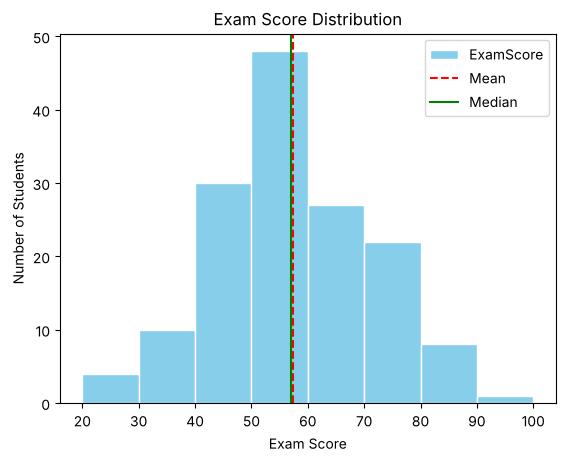

In [ ]:
# Exam scores with the mean and median marked
df["ExamScore"].plot(kind="hist", bins=range(20, 101, 10), color="skyblue", edgecolor="white")
plt.axvline(df["ExamScore"].mean(), color="red", linestyle="--", label="Mean")
plt.axvline(df["ExamScore"].median(), color="green", label="Median")
plt.title("Exam Score Distribution")
plt.xlabel("Exam Score")
plt.ylabel("Number of Students")
plt.legend()
plt.show()

## 2. Mean, median and mode

In [ ]:
# Mean, median and mode of exam scores
scores = df["ExamScore"]
print("Mean:", round(scores.mean(), 2))
print("Median:", scores.median())
print("Mode:", scores.mode().tolist())
print("Students with the mode:", (scores == scores.mode()[0]).sum(), "of", len(scores))

Mean: 57.39
Median: 57.0
Mode: [59.0]
Students with the mode: 9 of 150


In [ ]:
# mode() returns a list, because a column can have more than one most frequent value
for col in ["StudyHours", "Attendance", "PreviousScore", "Class"]:
    modes = df[col].mode().tolist()
    each = " each" if len(modes) > 1 else ""
    print(f"{col:<14} mode {modes} ({(df[col] == modes[0]).sum()} students{each})")

StudyHours     mode [3.5] (26 students)
Attendance     mode [82.0] (9 students)
PreviousScore  mode [54, 57, 60, 68] (6 students each)
Class          mode ['A', 'B'] (49 students each)


In [ ]:
# Compare the mean and median of exam scores in each class
print(df.groupby("Class")["ExamScore"].agg(["count", "mean", "median"]).round(1))

         count  mean  median
Class                       
A           49  58.2    59.0
B           49  56.8    56.0
C           47  57.0    57.0
Unknown      5  57.8    57.0


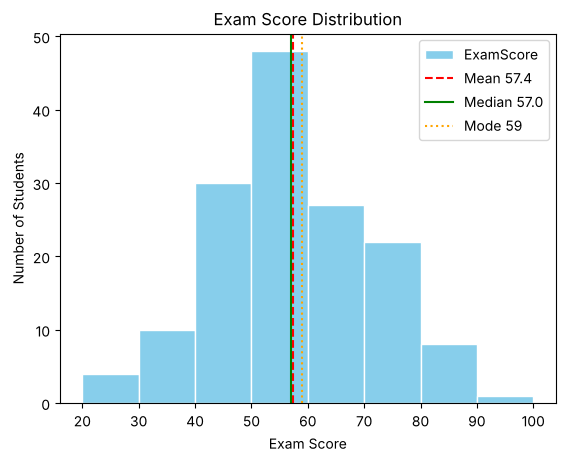

In [ ]:
# Exam scores with the mean, median and mode marked
df["ExamScore"].plot(kind="hist", bins=range(20, 101, 10), color="skyblue", edgecolor="white")
plt.axvline(scores.mean(), color="red", linestyle="--", label=f"Mean {scores.mean():.1f}")
plt.axvline(scores.median(), color="green", linestyle="-", label=f"Median {scores.median():.1f}")
plt.axvline(scores.mode()[0], color="orange", linestyle=":", label=f"Mode {scores.mode()[0]:.0f}")
plt.title("Exam Score Distribution")
plt.xlabel("Exam Score")
plt.ylabel("Number of Students")
plt.legend()
plt.show()

In [ ]:
# One wrong value: what if S8's impossible 750 from Day 4 were still in the data?
with_error = pd.concat([scores, pd.Series([750.0])])
print(f"Mean:   {scores.mean():.2f} -> {with_error.mean():.2f}")
print(f"Median: {scores.median():.2f} -> {with_error.median():.2f}")

Mean:   57.39 -> 61.97
Median: 57.00 -> 57.00


In [ ]:
# How far apart are the mean and median in each column?
cols = ["StudyHours", "Attendance", "PreviousScore", "ExamScore"]
gap = pd.DataFrame({"mean": df[cols].mean(), "median": df[cols].median()})
gap["mean - median"] = gap["mean"] - gap["median"]
print(gap.round(2))

                mean  median  mean - median
StudyHours      3.57     3.5           0.07
Attendance     79.49    80.0          -0.51
PreviousScore  62.66    62.0           0.66
ExamScore      57.39    57.0           0.39


## 3. Range, variance and standard deviation

In [ ]:
# Range, variance and standard deviation of exam scores
print("Range:", scores.max() - scores.min())
print("Sample variance (ddof=1):", round(scores.var(), 2))
print("Sample standard deviation (ddof=1):", round(scores.std(), 2))
print("Population variance (ddof=0):", round(scores.var(ddof=0), 2))
print("Population standard deviation (ddof=0):", round(scores.std(ddof=0), 2))

Range: 67.0
Sample variance (ddof=1): 192.13
Sample standard deviation (ddof=1): 13.86
Population variance (ddof=0): 190.85
Population standard deviation (ddof=0): 13.81


In [ ]:
# Step by step for the first five students (S1-S5, the real students from Days 2-4)
first5 = df["ExamScore"].head(5)
deviation = first5 - first5.mean()
print(pd.DataFrame({"Student": df["Student"].head(5), "score": first5, "deviation": deviation, "squared": deviation ** 2}).to_string(index=False))
squares = (deviation ** 2).sum()
print("\nMean:", first5.mean(), "| sum of squared deviations:", squares)
print("Sample variance, divide by n - 1 = 4:", squares / 4, "| pandas var():", first5.var())
print("Population variance, divide by n = 5:", squares / 5, "| pandas var(ddof=0):", first5.var(ddof=0))
print("Sample standard deviation:", round(first5.std(), 2))

Student  score  deviation  squared
     S1   35.0      -20.0    400.0
     S2   45.0      -10.0    100.0
     S3   55.0        0.0      0.0
     S4   65.0       10.0    100.0
     S5   75.0       20.0    400.0

Mean: 55.0 | sum of squared deviations: 1000.0
Sample variance, divide by n - 1 = 4: 250.0 | pandas var(): 250.0
Population variance, divide by n = 5: 200.0 | pandas var(ddof=0): 200.0
Sample standard deviation: 15.81


In [ ]:
# Spread of each numerical column (std / mean compares columns with different units)
cols = ["Age", "StudyHours", "Attendance", "PreviousScore", "ExamScore"]
spread = pd.DataFrame({
    "min": df[cols].min(),
    "max": df[cols].max(),
    "range": df[cols].max() - df[cols].min(),
    "variance": df[cols].var(),
    "std": df[cols].std(),
    "std / mean": df[cols].std() / df[cols].mean(),
}).round(2)
print(spread)

                min    max  range  variance    std  std / mean
Age            10.0   12.0    2.0      0.64   0.80        0.07
StudyHours      0.5    7.0    6.5      1.83   1.35        0.38
Attendance     54.0  100.0   46.0     99.37   9.97        0.13
PreviousScore  27.0   99.0   72.0    218.45  14.78        0.24
ExamScore      24.0   91.0   67.0    192.13  13.86        0.24


In [ ]:
# Compare the spread of exam scores across classes
print(df.groupby("Class")["ExamScore"].agg(["count", "mean", "std"]).round(1))

         count  mean   std
Class                     
A           49  58.2  14.0
B           49  56.8  14.4
C           47  57.0  13.5
Unknown      5  57.8  14.3


In [ ]:
# How many students are within 1 and 2 standard deviations of the mean?
mean, std = scores.mean(), scores.std()
within1 = scores.between(mean - std, mean + std).mean()
within2 = scores.between(mean - 2 * std, mean + 2 * std).mean()
print(f"Mean {mean:.1f}, standard deviation {std:.1f}")
print(f"Within 1 std ({mean - std:.1f} to {mean + std:.1f}): {within1:.0%} of students")
print(f"Within 2 std ({mean - 2 * std:.1f} to {mean + 2 * std:.1f}): {within2:.0%} of students")

Mean 57.4, standard deviation 13.9
Within 1 std (43.5 to 71.2): 70% of students
Within 2 std (29.7 to 85.1): 96% of students


## 4. Quartiles and percentiles

In [ ]:
# Quartiles, the interquartile range and percentiles of exam scores
print("Q1 (25th percentile):", scores.quantile(0.25))
print("Q2 (median):", scores.quantile(0.50))
print("Q3 (75th percentile):", scores.quantile(0.75))
print("IQR:", scores.quantile(0.75) - scores.quantile(0.25))
print()
for p in [10, 25, 50, 75, 90]:
    print(f"{p}th percentile: {scores.quantile(p / 100)}")

Q1 (25th percentile): 47.0
Q2 (median): 57.0
Q3 (75th percentile): 67.0
IQR: 20.0

10th percentile: 40.0
25th percentile: 47.0
50th percentile: 57.0
75th percentile: 67.0
90th percentile: 76.1


In [ ]:
# Percentiles depend on how you interpolate between two values; pandas uses "linear" by default
for method in ["linear", "lower", "higher", "nearest", "midpoint"]:
    print(f"{method:<9} 90th percentile: {scores.quantile(0.90, interpolation=method)}")

linear    90th percentile: 76.1
lower     90th percentile: 76.0
higher    90th percentile: 77.0
nearest   90th percentile: 76.0
midpoint  90th percentile: 76.5


In [ ]:
# Percentile rank is not a percentage mark: compare three real students
for student in ["S1", "S5", "S9"]:
    score = df.loc[df["Student"] == student, "ExamScore"].iloc[0]
    rank = (scores < score).mean() * 100          # the share of students who scored lower
    print(f"{student}: {score:.0f} marks out of 100, higher than {rank:.0f}% of students")

S1: 35 marks out of 100, higher than 5% of students
S5: 75 marks out of 100, higher than 87% of students
S9: 80 marks out of 100, higher than 94% of students


In [ ]:
# Quartiles and IQR of exam scores in each class
q = df.groupby("Class")["ExamScore"].quantile([0.25, 0.50, 0.75]).unstack()
q.columns = ["Q1", "median", "Q3"]
q["IQR"] = q["Q3"] - q["Q1"]
print(q)

           Q1  median    Q3   IQR
Class                            
A        48.0    59.0  67.0  19.0
B        50.0    56.0  65.0  15.0
C        47.0    57.0  67.5  20.5
Unknown  48.0    57.0  71.0  23.0


In [ ]:
# The top 10%: students at or above the 90th percentile
cutoff = scores.quantile(0.90)
top = df[scores >= cutoff]
print(f"90th percentile: {cutoff} | students at or above it: {len(top)}")
print(top["Class"].value_counts().sort_index().to_string())

90th percentile: 76.1 | students at or above it: 15
Class
A    6
B    6
C    3


## 5. Comparing distributions and interpreting statistics

In [ ]:
# Compare exam scores by class: centre (mean, median) and spread (std, IQR)
summary = df.groupby("Class")["ExamScore"].agg(["count", "mean", "median", "std"])
summary["IQR"] = (df.groupby("Class")["ExamScore"].quantile(0.75)
                  - df.groupby("Class")["ExamScore"].quantile(0.25))
print(summary.round(2))

         count   mean  median    std   IQR
Class                                     
A           49  58.24    59.0  13.96  19.0
B           49  56.82    56.0  14.44  15.0
C           47  57.04    57.0  13.50  20.5
Unknown      5  57.80    57.0  14.31  23.0


In [ ]:
# Distribution shape: skew near 0 is symmetric; positive is right-skewed, negative left-skewed
for col in ["Age", "StudyHours", "Attendance", "PreviousScore", "ExamScore"]:
    s = df[col].skew()
    shape = "roughly symmetric" if abs(s) < 0.5 else ("right-skewed" if s > 0 else "left-skewed")
    print(f"{col:<14} skew {s:5.2f}  mean {df[col].mean():6.2f}  median {df[col].median():6.2f}  {shape}")

Age            skew -0.04  mean  11.02  median  11.00  roughly symmetric
StudyHours     skew -0.00  mean   3.57  median   3.50  roughly symmetric
Attendance     skew -0.12  mean  79.49  median  80.00  roughly symmetric
PreviousScore  skew  0.17  mean  62.66  median  62.00  roughly symmetric
ExamScore      skew -0.01  mean  57.39  median  57.00  roughly symmetric


In [ ]:
# Our columns are all symmetric, so here is a small made-up example of each skewed shape
right = pd.Series([1, 1, 2, 2, 2, 3, 3, 4, 6, 15])          # e.g. hours of homework: most low, a few very high
left = pd.Series([40, 85, 88, 90, 91, 92, 93, 94, 95, 96])  # e.g. an easy test: most high, a few low
for name, s in [("Right-skewed", right), ("Left-skewed", left)]:
    print(f"{name}: mean {s.mean():.1f}, median {s.median():.1f}, skew {s.skew():.2f}")

Right-skewed: mean 3.9, median 2.5, skew 2.49
Left-skewed: mean 86.4, median 91.5, skew -2.94


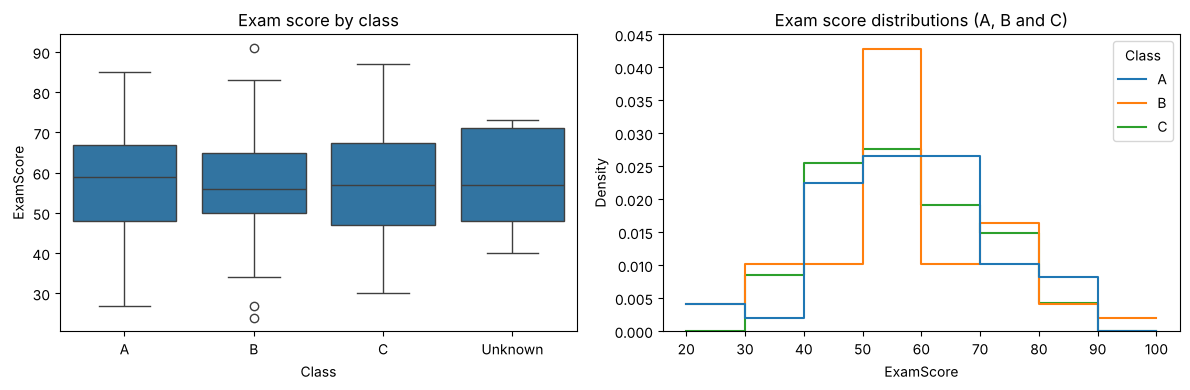

In [ ]:
# Compare the shapes: a box plot and overlaid histograms of exam scores by class
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
order = ["A", "B", "C", "Unknown"]
sns.boxplot(data=df, x="Class", y="ExamScore", order=order, ax=axes[0])
axes[0].set_title("Exam score by class")
sns.histplot(data=df[df["Class"] != "Unknown"], x="ExamScore", hue="Class", bins=range(20, 101, 10),
             stat="density", common_norm=False, element="step", fill=False, ax=axes[1])
axes[1].set_title("Exam score distributions (A, B and C)")
plt.tight_layout()
plt.show()

In [ ]:
# How big are the differences? Compare them with the spread (the standard deviation)
std = df["ExamScore"].std()
by_class = df.groupby("Class")["ExamScore"].mean()
band = pd.cut(df["Attendance"], bins=[0, 70, 85, 101], right=False, labels=["Low", "Medium", "High"])
by_band = df.groupby(band, observed=True)["ExamScore"].agg(["count", "mean", "median", "std"]).round(1)
print(by_band)
gap_class = by_class.max() - by_class.min()
gap_band = by_band["mean"].max() - by_band["mean"].min()
print(f"\nLargest gap between classes: {gap_class:.1f} points = {gap_class / std:.2f} standard deviations")
print(f"Gap between attendance bands: {gap_band:.1f} points = {gap_band / std:.2f} standard deviations")

            count  mean  median   std
Attendance                           
Low            24  50.3    47.0  13.3
Medium         80  55.5    55.5  13.3
High           46  64.3    63.5  12.5

Largest gap between classes: 1.4 points = 0.10 standard deviations
Gap between attendance bands: 14.0 points = 1.01 standard deviations


## 6. Mini project: statistical analysis of student performance

In [ ]:
# Mini project: load and inspect the dataset (8 real students, 142 synthetic)
df = pd.read_csv("student_data_150.csv")
print("Shape:", df.shape)
print(df["Source"].value_counts().to_string())
print()
print(df["ExamScore"].describe().round(2))

Shape: (150, 9)
Source
synthetic    142
original       8

count    150.00
mean      57.39
std       13.86
min       24.00
25%       47.00
50%       57.00
75%       67.00
max       91.00
Name: ExamScore, dtype: float64


In [ ]:
# Statistical summary table: centre, spread and position of every numerical column
cols = ["Age", "StudyHours", "Attendance", "PreviousScore", "ExamScore"]
table = pd.DataFrame({
    "mean": df[cols].mean(),
    "median": df[cols].median(),
    "range": df[cols].max() - df[cols].min(),
    "std": df[cols].std(),
    "Q1": df[cols].quantile(0.25),
    "Q3": df[cols].quantile(0.75),
}).round(2)
table["IQR"] = table["Q3"] - table["Q1"]
table["mode"] = [df[c].mode().tolist() for c in cols]
print(table)

                mean  median  range    std    Q1    Q3   IQR              mode
Age            11.02    11.0    2.0   0.80  10.0  12.0   2.0            [11.0]
StudyHours      3.57     3.5    6.5   1.35   2.5   4.5   2.0             [3.5]
Attendance     79.49    80.0   46.0   9.97  72.0  86.0  14.0            [82.0]
PreviousScore  62.66    62.0   72.0  14.78  52.0  73.0  21.0  [54, 57, 60, 68]
ExamScore      57.39    57.0   67.0  13.86  47.0  67.0  20.0            [59.0]


In [ ]:
# Class-wise statistics of exam scores
summary = df.groupby("Class")["ExamScore"].agg(["count", "mean", "median", "std", "min", "max"])
summary["IQR"] = (df.groupby("Class")["ExamScore"].quantile(0.75)
                  - df.groupby("Class")["ExamScore"].quantile(0.25))
print(summary.round(2))

         count   mean  median    std   min   max   IQR
Class                                                 
A           49  58.24    59.0  13.96  27.0  85.0  19.0
B           49  56.82    56.0  14.44  24.0  91.0  15.0
C           47  57.04    57.0  13.50  30.0  87.0  20.5
Unknown      5  57.80    57.0  14.31  40.0  73.0  23.0


In [ ]:
# Unusual observations: the 1.5 x IQR rule for all students, then within each class
q1, q3 = df["ExamScore"].quantile([0.25, 0.75])
low, high = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
print(f"All students: outside {low} to {high}:", df.loc[~df["ExamScore"].between(low, high), "Student"].tolist())
for cls, group in df.groupby("Class"):
    q1, q3 = group["ExamScore"].quantile([0.25, 0.75])
    low, high = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
    flagged = group[~group["ExamScore"].between(low, high)]
    print(f"Class {cls:<8} outside {low} to {high}: {flagged['ExamScore'].tolist()}")

All students: outside 17.0 to 97.0: []
Class A        outside 19.5 to 95.5: []
Class B        outside 27.5 to 87.5: [91.0, 24.0, 27.0]
Class C        outside 16.25 to 98.25: []
Class Unknown  outside 13.5 to 105.5: []


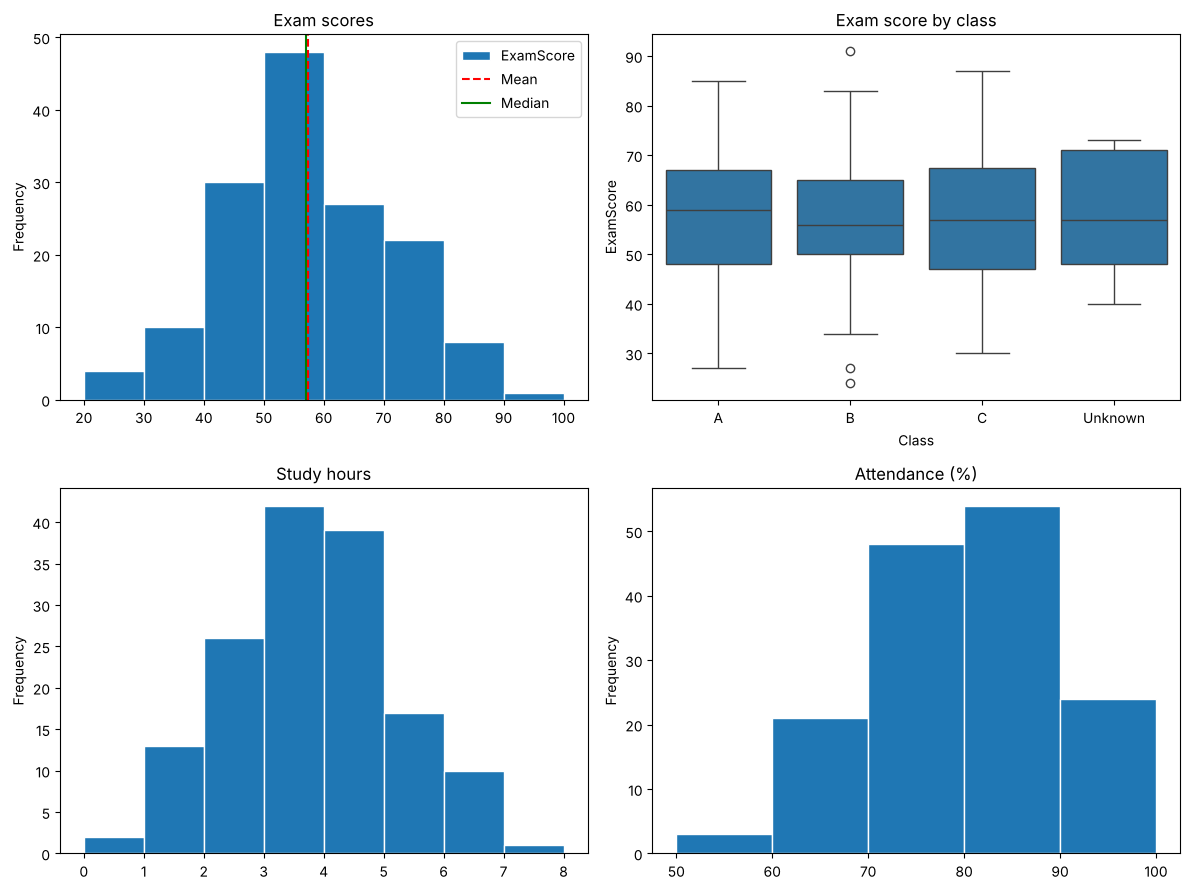

In [ ]:
# Visualizations: histogram with mean and median, box plot by class, histograms of other columns
import seaborn as sns

fig, axes = plt.subplots(2, 2, figsize=(12, 9))
df["ExamScore"].plot(kind="hist", bins=range(20, 101, 10), ax=axes[0, 0], edgecolor="white")
axes[0, 0].axvline(df["ExamScore"].mean(), color="red", linestyle="--", label="Mean")
axes[0, 0].axvline(df["ExamScore"].median(), color="green", label="Median")
axes[0, 0].legend()
axes[0, 0].set_title("Exam scores")
sns.boxplot(data=df, x="Class", y="ExamScore", order=["A", "B", "C", "Unknown"], ax=axes[0, 1])
axes[0, 1].set_title("Exam score by class")
df["StudyHours"].plot(kind="hist", bins=range(0, 9), ax=axes[1, 0], edgecolor="white", title="Study hours")
df["Attendance"].plot(kind="hist", bins=range(50, 101, 10), ax=axes[1, 1], edgecolor="white", title="Attendance (%)")
plt.tight_layout()
plt.show()

In [ ]:
# Answers to the project questions, computed from the data
s = df["ExamScore"]
means = df.groupby("Class")["ExamScore"].mean().round(2)
stds = df.groupby("Class")["ExamScore"].std().round(2)
print("1. Highest average:", means.idxmax(), means.max(), "| lowest:", means.idxmin(), means.min())
print("2. Greatest variation:", stds.idxmax(), "std", stds.max())
print(f"3. Mean {s.mean():.2f} vs median {s.median():.1f}: a gap of {s.mean() - s.median():.2f} points")
print(f"4. IQR {s.quantile(0.75) - s.quantile(0.25)}: the middle half of students score {s.quantile(0.25)} to {s.quantile(0.75)}")

1. Highest average: A 58.24 | lowest: B 56.82
2. Greatest variation: B std 14.44
3. Mean 57.39 vs median 57.0: a gap of 0.39 points
4. IQR 20.0: the middle half of students score 47.0 to 67.0
